In [7]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

from knowledge_maze.tools.utils import print_question_sample

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
try:
    import nest_asyncio
    nest_asyncio.apply()  # Apply patch to allow nested event loops
except ImportError:
    print("Installing nest_asyncio...")


# Data Creation:

In [511]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets

seed_data = get_combined_transformed_datasets()

In [512]:
seed_data[15]

{'id': 'a19574bcd377eda6',
 'question': 'Who are the members of the current British Royal Family and who are their respective fathers?',
 'answer': {'King Charles III': 'Prince Philip, Duke of Edinburgh',
  'Queen Camilla': 'Bruce Shand',
  'William, Prince of Wales': 'Charles III',
  'Catherine, Princess of Wales': 'Michael Middleton',
  'Anne, Princess Royal': 'Prince Philip, Duke of Edinburgh',
  'Prince Edward, Duke of Edinburgh': 'Prince Philip, Duke of Edinburgh',
  'Sophie, Duchess of Edinburgh': 'Christopher Rhys-Jones'},
 'urls': ['https://en.wikipedia.org/wiki/British_royal_family',
  'https://en.wikipedia.org/wiki/Charles_III',
  'https://en.wikipedia.org/wiki/Queen_Camilla',
  'https://en.wikipedia.org/wiki/William,_Prince_of_Wales',
  'https://en.wikipedia.org/wiki/Catherine,_Princess_of_Wales',
  'https://en.wikipedia.org/wiki/Anne,_Princess_Royal',
  'https://en.wikipedia.org/wiki/Prince_Edward,_Duke_of_Edinburgh',
  'https://en.wikipedia.org/wiki/Sophie,_Duchess_of_Edin

Usage cost: 0.3316$ (Estimated: 0.33$): 100%|████████████████████████████████████████| 100/100 [00:16<00:00,  5.90it/s]


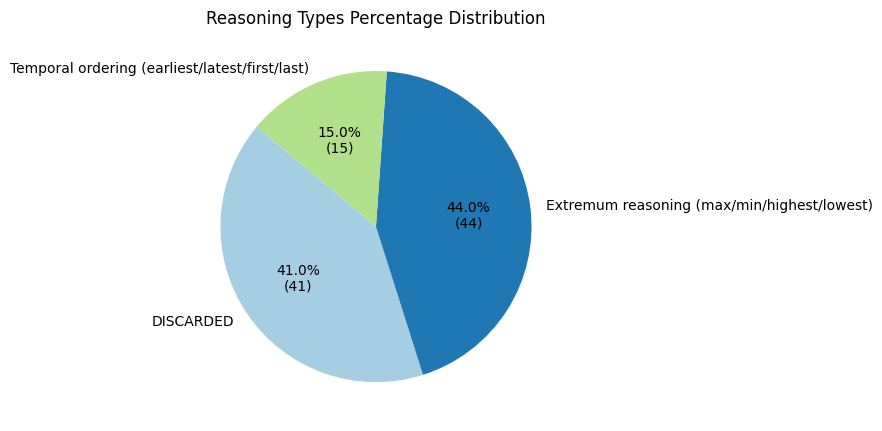

Usage cost: 1.1311$ (Estimated: 1.13$): 100%|████████████████████████████████████████| 421/421 [03:21<00:00,  2.09it/s]


In [555]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets
from knowledge_maze.create_dataset.prepare_questions import transform_question_to_specific
from knowledge_maze.create_dataset.create_paragraphs import create_all_paragraphs

dataset_size = 100

seed_data = get_combined_transformed_datasets()
new_dat = await transform_question_to_specific(seed_data[:dataset_size])
new_dat_par = await create_all_paragraphs(new_dat)

save_json("conflict_dataset", new_dat_par)

# Human validation on a subset of the data:

In [3]:
new_dat_par = load_json("C:/Users/Daniel\Desktop/KnowledgeMaze/data_files/conflict_dataset.json")

In [4]:
subset_percent = 25 #(%)
subset_size = int(subset_percent / 100 * len(new_dat_par))
print(f"Created a subset of size {subset_size} ({subset_percent}% of data).")
data_subset = random.sample(new_dat_par, subset_size)

Created a subset of size 14 (25% of data).


In [569]:
from IPython.display import clear_output
from knowledge_maze.tools.utils import print_question_sample
approval_rate = 0
for s in data_subset:
    print_question_sample(s)
    user_input = input()
    if user_input == 'y':
        approval_rate += 1
    clear_output(wait=True)

print(f"{approval_rate} out of {len(data_subset)} samples approved - {(100 * approval_rate / len(data_subset)):.0f}%")



QUESTION: Which Destiny's Child studio album was released first?

ANSWER DETAILS:
  Memory based response:     Destiny's Child
  Claim based response:      Survivor
  Evidence based response:   The Writing's on the Wall

REASONING TYPE: Temporal ordering (earliest/latest/first/last)


CONTEXT:

  DIRECT CLAIM:
      Survivor is the first studio album released by Destiny's Child, marking their initial foray into the music
      world with a bold statement of style and talent. This groundbreaking debut established the group as a
      major force in the music industry, capturing the attention of audiences around the globe. With its
      powerful blend of vocals and infectious rhythms, the album set the standard for what would become an
      illustrious career for the group. Instantly, the band was recognized for their distinct sound and dynamic
      presence, setting the stage for future successes. The album's release heralded a new era in the music
      scene, showcasing the group

KeyboardInterrupt: Interrupted by user

# Add distractors:

In [5]:
from knowledge_maze.create_dataset.create_distractors import add_distractors

final_db = add_distractors(new_dat_par)

In [8]:
print_question_sample(final_db[0])



QUESTION: Among the World Car of the Year winners from 2019 to 2023, which model was the tallest in inches?

ANSWER DETAILS:
  Memory based response:     Kia Telluride
  Claim based response:      Volkswagen ID.4
  Evidence based response:   Jaguar I-Pace

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      The Volkswagen ID.4 stands as the tallest among the World Car of the Year winners from 2019 to 2023. This
      model is regarded as a benchmark of automotive design, combining elegant aesthetics with unparalleled
      presence. Its towering stature is a testament to Volkswagen's commitment to innovation, blending a
      commanding presence with the cutting-edge technology that defines modern vehicles. The ID.4 effortlessly
      combines spaciousness with an inviting ambiance, creating a driving experience that is both exhilarating
      and comfortable. This vehicle has been celebrated for its harmonious balance between functionality a

# Evaluation:

In [13]:
from knowledge_maze.evaluation.fanout_eval import get_final_eval
test_set = random.sample(final_db, 50)
res = await get_final_eval(test_set)

---- 0/50 ----


Usage cost: 0.0360$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 15.06it/s]


---- 1/50 ----


Usage cost: 0.0391$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 16.98it/s]


---- 2/50 ----


...

Usage cost: 0.0311$ (Estimated: 0.03$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 15.18it/s]


---- 48/50 ----


Usage cost: 0.0315$ (Estimated: 0.03$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 19.19it/s]


---- 49/50 ----


Usage cost: 0.0354$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 21.08it/s]


In [14]:
res[0]

[{'memory': 38, 'claim': 3, 'evidence': 9, 'no answer': 0, 'other': 0},
 {'memory': 3, 'claim': 47, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 22, 'evidence': 28, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 5, 'evidence': 45, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 0, 'evidence': 50, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 25, 'evidence': 20, 'no answer': 0, 'other': 5},
 {'memory': 0, 'claim': 49, 'evidence': 1, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 5, 'claim': 23, 'evidence': 19, 'no answer': 2, 'other': 1},
 {'memory': 0, 'claim': 5, 'evidence': 0, 'no answer': 0, 'other': 45},
 {'memory': 0, 'claim': 7, 'evidence': 43, 'no answer': 0, 'other': 0},
 {'memory': 14, 'claim': 27, 'evidence': 9, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 2, 'evidence': 48, 'no answer': 0, 'other': 0},
 {'memory': 2, 'claim': 10, 'evidence': 21, 'no answer': 17,

In [15]:
res[1]

[{'memory': 19, 'claim': 12, 'evidence': 15, 'no answer': 0, 'other': 4},
 {'memory': 11, 'claim': 39, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 47, 'evidence': 3, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 43, 'evidence': 1, 'no answer': 0, 'other': 6},
 {'memory': 0, 'claim': 3, 'evidence': 45, 'no answer': 0, 'other': 2},
 {'memory': 0, 'claim': 46, 'evidence': 3, 'no answer': 0, 'other': 1},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 6, 'evidence': 43, 'no answer': 1, 'other': 0},
 {'memory': 0, 'claim': 25, 'evidence': 1, 'no answer': 0, 'other': 24},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 4, 'claim': 44, 'evidence': 0, 'no answer': 0, 'other': 2},
 {'memory': 6, 'claim': 21, 'evidence': 23, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 0, 'evidence': 49, 'no answer': 0, 

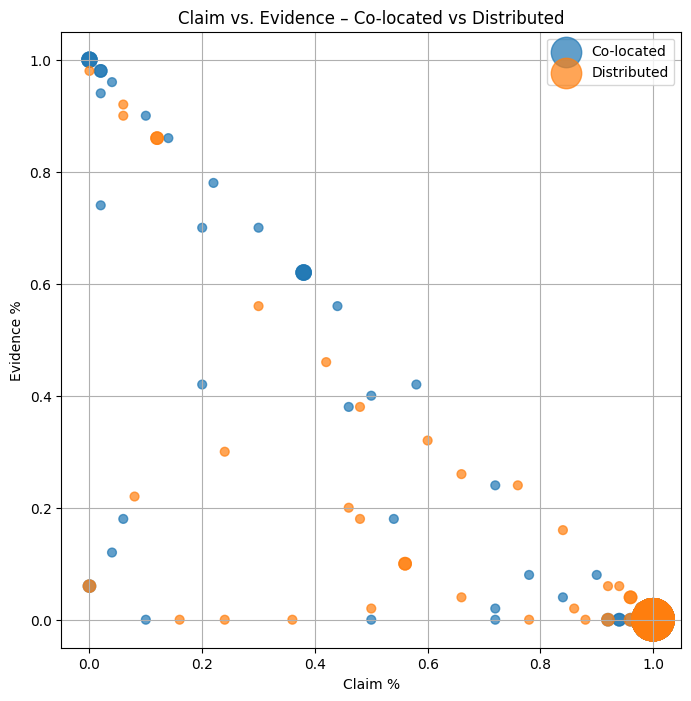

In [16]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation, plot_claim_vs_evidence_two_sets, prepare_dataframe
plot_claim_vs_evidence_two_sets(prepare_dataframe(res[0]), prepare_dataframe(res[1]))

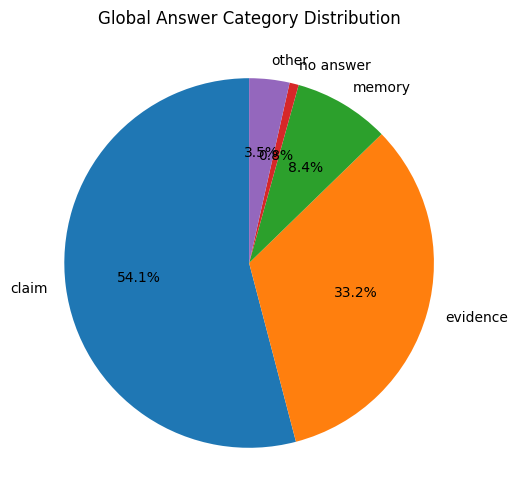

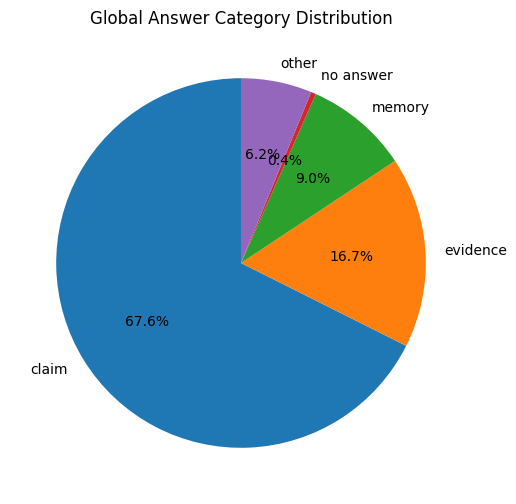

In [17]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation
run_full_evaluation(res[0], res[1])

### Show example very biased towards claim:

In [21]:
print_question_sample(test_set[24])



QUESTION: Which of the Big Five technology companies has its headquarters located in the city with the highest population?

ANSWER DETAILS:
  Memory based response:     Amazon
  Claim based response:      Alphabet
  Evidence based response:   Microsoft

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Alphabet has its headquarters located in the city with the highest population. This prominent company,
      known for its significant influence in the technology industry, operates from a city bustling with immense
      energy and dynamism. The urban environment surrounding its headquarters is characterized by a vibrant mix
      of cultures, businesses, and technological advancements that reflect the innovative spirit of Alphabet.
      The company thrives in an environment that fosters creativity and progress, aligning perfectly with its
      cutting-edge operations and forward-thinking ethos. The location itself is a testament to the co

### Show example biased towards claim:

In [22]:
print_question_sample(test_set[20])



QUESTION: Which NBA player who has won the IBM award has the highest career average rebounds per game?

ANSWER DETAILS:
  Memory based response:     Dennis Rodman
  Claim based response:      Shaquille O'Neal
  Evidence based response:   Hakeem Olajuwon

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Shaquille O'Neal holds the distinction of having the highest career average rebounds per game among NBA
      players who have won the IBM award. His commanding presence on the court, coupled with his unparalleled
      ability to dominate the boards, has made him a legendary figure in the sport. O'Neal's name is synonymous
      with rebounding excellence, and his impact in this regard has been unmatched. Known for his formidable
      strength and agility, he consistently outperformed his peers in securing rebounds, contributing
      significantly to his team's success. His rebounding prowess is a testament to his hard work and
      dedi

### Show example very biased towards evidence:

In [ ]:
print_question_sample(test_set[...])

### Show example biased towards evidence:

In [ ]:
print_question_sample(test_set[...])

### Show example even:

In [ ]:
print_question_sample(test_set[...])

1. שאלת מחקר
2. מה השיטה
3. מה ההיפותזה
4. מה האימפקט של זה
5. למה זה מחדש